#  **`dp`**
### обернене відношення роздільності акумулятора до роздільності вхідного зображення. За документацією OpenCV: при dp=1 акумулятор має таку саму ширину й висоту, як зображення; при dp=2 — удвічі меншу ширину й висоту
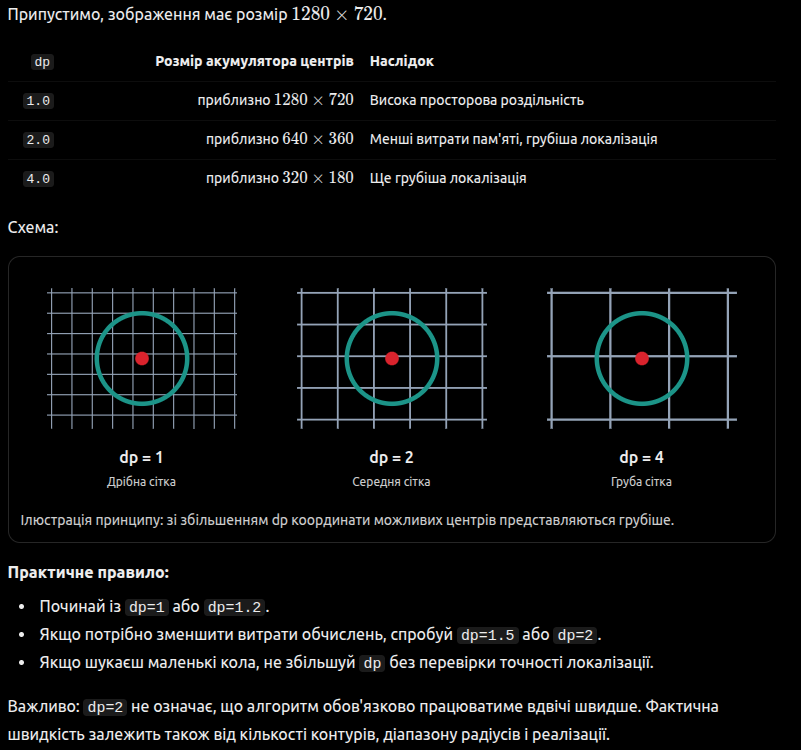
___
# **`minDist`**
### мінімальна відстань між центрами
    $$d=\sqrt{(a_1-a_2)^2+(b_1-b_2)^2}$$
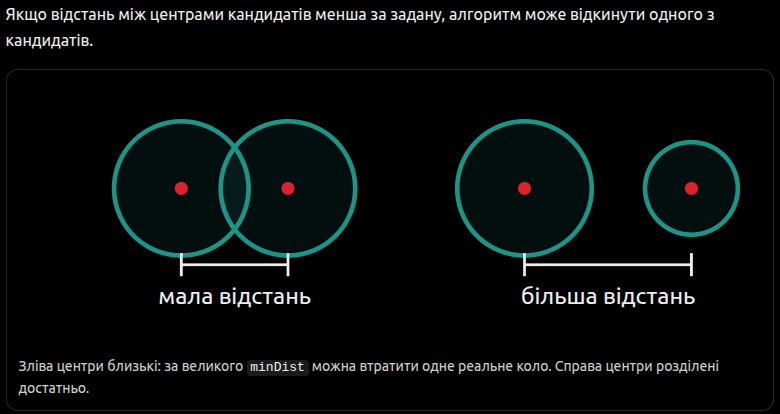
___
# **`param1`**
### поріг 'Canny`

Для `HOUGH_GRADIENT` цей параметр задає верхній поріг внутрішнього детектора Canny. Нижній поріг у цій реалізації дорівнює приблизно половині верхнього:
$$T_{\text{high}}=\text{param1}$$
$$T_{\text{low}}=\frac{\text{param1}}{2}$$

    param1 = 60   # чутливіше до слабких контурів
    param1 = 100  # початкова оцінка
    param1 = 180  # відсікає більше слабких градієнтів
___
# **`param2`**
### поріг прийняття кола
Для `HOUGH_GRADIENT` задає поріг акумулятора під час виявлення центрів кіл.

Якщо різні точки контуру підтримують різні можливі центри. Чим більше узгоджених свідчень на користь певного центра, тим сильніший кандидат.
Спрощена модель:
$$A(a,b)=\sum_i w_i(a,b)$$

де \(A(a,b)\) — умовна сила підтримки кандидата на центр, а \(w_i\) — внесок точок контуру. Це концептуальна модель, а не точна формула внутрішнього акумулятора OpenCV.

Кандидати з недостатньою підтримкою відкидаються.

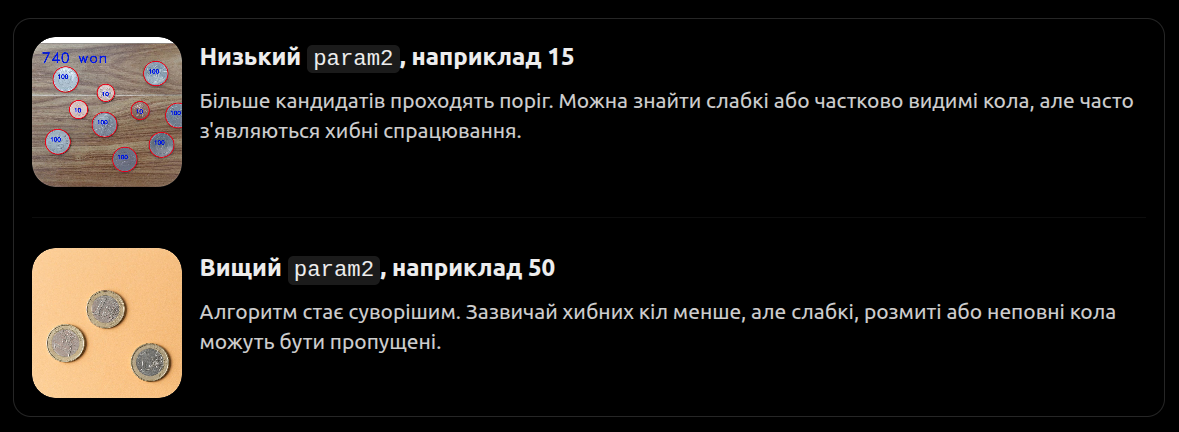
___
        param1 керує чутливістю внутрішнього виявлення контурів Canny.
        param2 керує прийняттям кандидатів на центри кіл.
___

# `minRadius` і `maxRadius` — діапазон радіусів
___
    circles = cv.HoughCircles(
        gray_blur,
        method=cv.HOUGH_GRADIENT,
        dp=dp,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )

    if circles is not None:
        circles = np.round(circles[0]).astype(int)

    for x, y, r in circles:
        cv.circle(img, (x, y), r, (0, 255, 0), 2)
        cv.circle(img, (x, y), 2, (0, 0, 255), -1)

    cv.imshow("Detected circles", img)
    cv.waitKey(0)
    cv.destroyAllWindows()

In [1]:
from dataclasses import dataclass

import cv2 as cv
import numpy as np
from matplotlib import pyplot as plt
from core.entities.constants import Paths as p

In [2]:
IMAGE_PATH = p.IMAGE_ASSETS / "tesla.png"


img = cv.imread(IMAGE_PATH)

if img is None:
    raise ValueError("Could not read the image.")

scale_factor = 1 / 2
h, w, _ = img.shape

img = cv.resize(img, (int(w * scale_factor), int(h * scale_factor)))

img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

In [4]:
blur_titles = ["none", "median blur", "gaussian blur"]

In [5]:
@dataclass(frozen=True)
class TBarNames:
    BLUR_FUNC: str = "blur_function"
    BLUR_KERNEL: str = "blur_kernel"
    DP: str = "dp"
    MIN_DISTANCE: str = "min_distance x10"
    PARAM_1: str = "param_1"
    PARAM_2: str = "param_2"
    MIN_RADIUS: str = "min_radius"
    MAX_RADIUS: str = "max_radius"


In [6]:
def callback(value:int) -> None:
    pass

In [7]:
window_name = "Hough Circle"
cv.namedWindow(window_name)

cv.createTrackbar(TBarNames.BLUR_FUNC, window_name, 1, 2, callback)

cv.createTrackbar(TBarNames.BLUR_KERNEL, window_name, 11, 21, callback)
cv.setTrackbarMin(TBarNames.BLUR_KERNEL, window_name, 1)

cv.createTrackbar(TBarNames.DP, window_name, 1, 10, callback)
cv.setTrackbarMin(TBarNames.DP, window_name, 1)

cv.createTrackbar(TBarNames.MIN_DISTANCE, window_name, 50, 100, callback) # real value will be x10 with step 10
cv.setTrackbarMin(TBarNames.MIN_DISTANCE, window_name, 1)

cv.createTrackbar(TBarNames.PARAM_1, window_name, 100, 255, callback)
cv.setTrackbarMin(TBarNames.PARAM_1, window_name, 1)

cv.createTrackbar(TBarNames.PARAM_2, window_name, 50, 255, callback)
cv.setTrackbarMin(TBarNames.PARAM_2, window_name, 1)

cv.createTrackbar(TBarNames.MIN_RADIUS, window_name, 0, 300, callback)

cv.createTrackbar(TBarNames.MAX_RADIUS, window_name, 150, 300, callback)
cv.setTrackbarMin(TBarNames.MAX_RADIUS, window_name, 1)

while True:
    if cv.waitKey(1) == ord("q"):
        break

    gray = img_gray.copy()
    overlay = img.copy()

    ########################
    # BLUR
    ########################
    blur_func_idx = cv.getTrackbarPos(TBarNames.BLUR_FUNC, window_name)

    if blur_func_idx:
        kernel = cv.getTrackbarPos(TBarNames.BLUR_KERNEL, window_name)

        # blur kernel must be odd
        if kernel % 2 == 0:
            kernel += 1
            cv.setTrackbarPos(TBarNames.BLUR_KERNEL, window_name, kernel)

        if blur_func_idx == 1:
            gray = cv.medianBlur(gray, kernel)
        else:
            gray = cv.GaussianBlur(gray, (kernel, kernel), 0)
    else:
        kernel = "None"

    ########################
    # HOUGH CIRCLE
    ########################

    dp = cv.getTrackbarPos(TBarNames.DP, window_name)
    min_dist = cv.getTrackbarPos(TBarNames.MIN_DISTANCE, window_name) * 10
    param1 = cv.getTrackbarPos(TBarNames.PARAM_1, window_name)
    param2 = cv.getTrackbarPos(TBarNames.PARAM_2, window_name)
    min_radius = cv.getTrackbarPos(TBarNames.MIN_RADIUS, window_name)
    max_radius = cv.getTrackbarPos(TBarNames.MAX_RADIUS, window_name)

    circles = cv.HoughCircles(
        gray,
        method=cv.HOUGH_GRADIENT,
        dp=dp,
        minDist=min_dist,
        param1=param1,
        param2=param2,
        minRadius=min_radius,
        maxRadius=max_radius
    )

    if circles is not None:
        circles = np.uint16(np.around(circles))

        for circle in circles[0, :]:
            cv.circle(overlay, (circle[0], circle[1]), circle[2], (0, 0, 255), 5)
            cv.circle(gray, (circle[0], circle[1]), circle[2], (255, 255, 255), 5)
    ########################
    # VISUALISE
    ########################
    text = (f"blur_func: {blur_titles[blur_func_idx]} | kernel: {kernel}\n"
            f"dp: {dp} | min_dist: {min_dist}\n"
            f"param1: {param1} | param2: {param2}\n"
            f"min_radius: {min_radius} | max_radius: {max_radius}")
    cv.putText(
        overlay,
        text,
        (30, 30),
        cv.FONT_HERSHEY_SIMPLEX,
        fontScale=1,
        color=(0, 0, 255),
    )

    cv.imshow(window_name, gray)
    cv.imshow("RESULT", overlay)




cv.destroyAllWindows()

(np.float64(-0.5), np.float64(1439.5), np.float64(900.5), np.float64(-0.5))

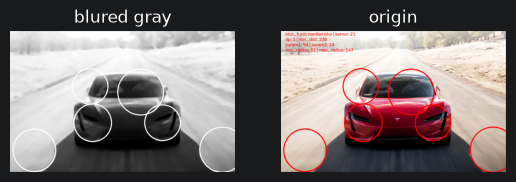

In [8]:
plt.figure()

plt.subplot(121)
plt.title("blured gray")
plt.imshow(gray, cmap="gray")
plt.axis('off')

plt.subplot(122)
plt.title("origin")
overlay = cv.cvtColor(overlay, cv.COLOR_BGR2RGB)
plt.imshow(overlay)
plt.axis('off')